# Assignment 1: EDA and Baselines
**CENG313 Introduction to Data Science, Group 55**
Kaggle competition: [DRW - Crypto Market Prediction](https://www.kaggle.com/competitions/drw-crypto-market-prediction)

Goal of this notebook:
1. Understand the data: what the rows, features and target look like, how clean it is, and how it behaves over time.
2. Establish baseline models on a leakage-free validation scheme, so Assignment 2 has clear numbers to beat.

Reusable code lives in `src/` (`data.py`, `models.py`, `utils.py`) and is imported below.

## 0. Setup

Runs in Google Colab or locally. In Colab the cell below clones the repository, asks for your `kaggle.json` and downloads the competition data (you must have accepted the competition rules on Kaggle).

In [1]:
import os
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if os.path.basename(os.getcwd()) != "GROUP55_CENG313":
        if not os.path.exists("GROUP55_CENG313"):
            !git clone -q https://github.com/zreik-blanc/GROUP55_CENG313.git
        %cd GROUP55_CENG313
    %pip install -q lightgbm kaggle
    KAGGLE_DIR = "/root/.kaggle"
    os.makedirs(KAGGLE_DIR, exist_ok=True)
    if not os.listdir(KAGGLE_DIR):
        # Upload your Kaggle credential from Settings > API: either kaggle.json or a text
        # file holding an API token. A bare token is saved as access_token, which the CLI reads.
        from google.colab import files
        for name, content in files.upload().items():
            text = content.decode().strip()
            target = "kaggle.json" if text.startswith("{") else "access_token"
            with open(os.path.join(KAGGLE_DIR, target), "w") as f:
                f.write(text)
            os.chmod(os.path.join(KAGGLE_DIR, target), 0o600)
            os.remove(name)
    if not os.path.exists("data/train.parquet"):
        !kaggle competitions download -c drw-crypto-market-prediction -p data
        !unzip -q -o data/*.zip -d data

DATA_DIR = "data"

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import MARKET_COLS, TARGET, feature_columns, load_test, load_train, time_split, x_columns
from src.eda import adversarial_validation, minute_grid, redundant_pairs
from src.models import BASELINES
from src.utils import memory_mb, pearson, write_submission

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 4)
pd.set_option("display.width", 160)

## 1. Load the data

In [3]:
train = load_train(DATA_DIR)
test = load_test(DATA_DIR)
print("train", train.shape, f"{memory_mb(train):,.0f} MB (float32)")
print("test ", test.shape, f"{memory_mb(test):,.0f} MB (float32)")
print("train period:", train.index.min(), "to", train.index.max())
print("test index:", test.index.name, test.index.min(), "to", test.index.max())
train.head()

train (525886, 786) 1,581 MB (float32)
test  (538150, 786) 1,614 MB (float32)
train period: 2023-03-01 00:00:00 to 2024-02-29 23:59:00
test index: ID 1 to 538150


,bid_qty,ask_qty,buy_qty,sell_qty,volume,X1,X2,X3,X4,X5,...,X772,X773,X774,X775,X776,X777,X778,X779,X780,label
2023-03-01 00:00:00,15.283000,8.425000,176.404999,44.984001,221.389008,0.181844,-0.637860,0.006652,0.136870,0.116698,...,0.333753,-0.009992,-0.695594,-0.444077,-0.191238,-0.184251,-0.471897,-0.625428,-0.553991,0.562539
2023-03-01 00:01:00,38.590000,2.336000,525.846008,321.950012,847.796021,0.489497,-0.075619,0.431594,0.522400,0.475255,...,0.333658,-0.010040,-0.696226,-0.452866,-0.200082,-0.188929,-0.472842,-0.625832,-0.554426,0.533686
2023-03-01 00:02:00,0.442000,60.250000,159.227005,136.369003,295.596008,0.260121,-0.444684,0.100695,0.224729,0.203282,...,0.333667,-0.010037,-0.696832,-0.461383,-0.208786,-0.193571,-0.473785,-0.626236,-0.554860,0.546505
2023-03-01 00:03:00,4.865000,21.016001,335.742004,124.962997,460.704987,0.099976,-0.666728,-0.123858,0.019197,0.014459,...,0.333174,-0.010279,-0.697391,-0.469628,-0.217350,-0.198175,-0.474726,-0.626639,-0.555294,0.357703
2023-03-01 00:04:00,27.158001,3.451000,98.411003,44.407001,142.817993,0.270893,-0.325973,0.116336,0.234311,0.214073,...,0.333171,-0.010283,-0.697940,-0.477622,-0.225780,-0.202745,-0.475666,-0.627043,-0.555728,0.362452


### Column groups

In [4]:
xcols = x_columns(train)
print(len(MARKET_COLS), "market columns:", MARKET_COLS)
print(len(xcols), "anonymized X columns, e.g.", xcols[:3], "...", xcols[-3:])
print("target:", TARGET)
print("test has the same columns:", list(test.columns) == list(train.columns))
print("test label values (placeholder?):", np.unique(test[TARGET])[:5])

5 market columns: ['bid_qty', 'ask_qty', 'buy_qty', 'sell_qty', 'volume']
780 anonymized X columns, e.g. ['X1', 'X2', 'X3'] ... ['X778', 'X779', 'X780']
target: label
test has the same columns: True
test label values (placeholder?): [0.]


## 2. Data quality

Missing values, constant columns, duplicate timestamps and gaps in the minute grid.

In [5]:
na_train = train.isna().sum()
print("train columns with NaN:", int((na_train > 0).sum()), "| NaN cells:", int(na_train.sum()))
print("test  NaN cells:", int(test.isna().sum().sum()))
print("duplicate timestamps in train:", int(train.index.duplicated().sum()))

x_std = train[xcols].std()
constant_x = x_std[x_std == 0].index.tolist()
print("constant X columns:", len(constant_x), constant_x[:10])

coverage, gap_sizes = minute_grid(train.index)
display(coverage.to_frame("minute grid").T)
print("most common gap sizes:")
print(gap_sizes.head(5).to_string())

train columns with NaN: 0 | NaN cells: 0


test  NaN cells: 0
duplicate timestamps in train: 0


constant X columns: 0 []


,expected_minutes,present,missing,missing_share,gaps,longest_gap
minute grid,527040,525886,1154,0.00219,273,0 days 00:35:00


most common gap sizes:
0 days 00:02:00    116
0 days 00:03:00     57
0 days 00:04:00     18
0 days 00:08:00     14
0 days 00:06:00     13


## 3. The target

`label` is an anonymized measure of the future price move. We look at its distribution, tails, autocorrelation and how its volatility changes over the year.

,count,mean,std,min,25%,50%,75%,max
label,525886.0,0.036126,1.009915,-24.416615,-0.381586,0.016261,0.434137,20.740271


skew -0.11   kurtosis 15.99   zero share 0.000%


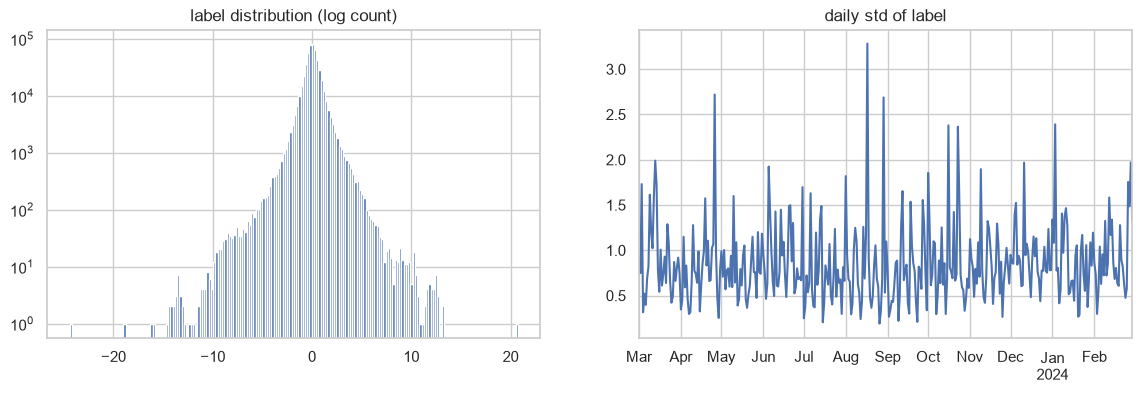

lag (min),1,2,3,5,10,30,60,1440
autocorr,0.981195,0.96271,0.945486,0.913684,0.84059,0.608568,0.378464,-0.023547


In [6]:
y = train[TARGET]
display(y.describe().to_frame().T)
print(f"skew {y.skew():.2f}   kurtosis {y.kurt():.2f}   zero share {(y == 0).mean():.3%}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].hist(y, bins=200)
ax[0].set_yscale("log")
ax[0].set_title("label distribution (log count)")
y.resample("1D").std().plot(ax=ax[1], title="daily std of label")
plt.show()

lags = [1, 2, 3, 5, 10, 30, 60, 1440]
pd.DataFrame({"lag (min)": lags, "autocorr": [y.autocorr(l) for l in lags]}).set_index("lag (min)").T

## 4. The five market features

`bid_qty`, `ask_qty` describe the order book, `buy_qty`, `sell_qty` the executed trades, `volume` the traded amount. We also derive two classic imbalance signals.

,count,mean,std,min,25%,50%,75%,max
bid_qty,525886.0,9.967947,15.645712,0.001,2.63400,6.415000,13.085000,1114.932007
ask_qty,525886.0,10.174160,15.889598,0.001,2.67800,6.538000,13.330000,1352.964966
buy_qty,525886.0,131.712677,307.184906,0.000,26.40700,57.014999,127.625999,17609.566406
sell_qty,525886.0,132.660080,309.728729,0.000,27.02025,58.044498,129.100498,17685.503906
volume,525886.0,264.372803,588.457581,0.000,60.68700,120.790501,256.730743,28685.345703


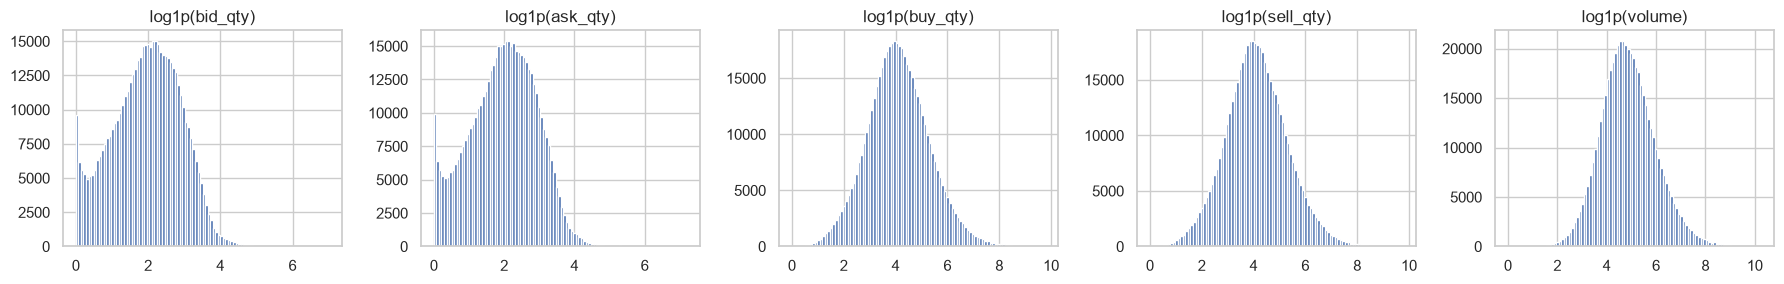

,pearson,spearman
bid_qty,-0.0132,-0.0014
ask_qty,-0.0158,-0.0270
buy_qty,0.0056,0.0006
sell_qty,0.0112,0.0108
volume,0.0088,0.0057
book_imbalance,0.0110,0.0164
flow_imbalance,-0.0061,-0.0159


In [7]:
display(train[MARKET_COLS].describe().T)

fig, axes = plt.subplots(1, 5, figsize=(18, 3))
for ax, c in zip(axes, MARKET_COLS):
    ax.hist(np.log1p(train[c]), bins=100)
    ax.set_title(f"log1p({c})")
plt.tight_layout()
plt.show()

derived = pd.DataFrame({
    "book_imbalance": (train.bid_qty - train.ask_qty) / (train.bid_qty + train.ask_qty),
    "flow_imbalance": (train.buy_qty - train.sell_qty) / (train.buy_qty + train.sell_qty),
}, index=train.index).replace([np.inf, -np.inf], np.nan)

both = pd.concat([train[MARKET_COLS], derived], axis=1)
pd.DataFrame({
    "pearson": both.corrwith(y),
    "spearman": both.corrwith(y, method="spearman"),
}).round(4)

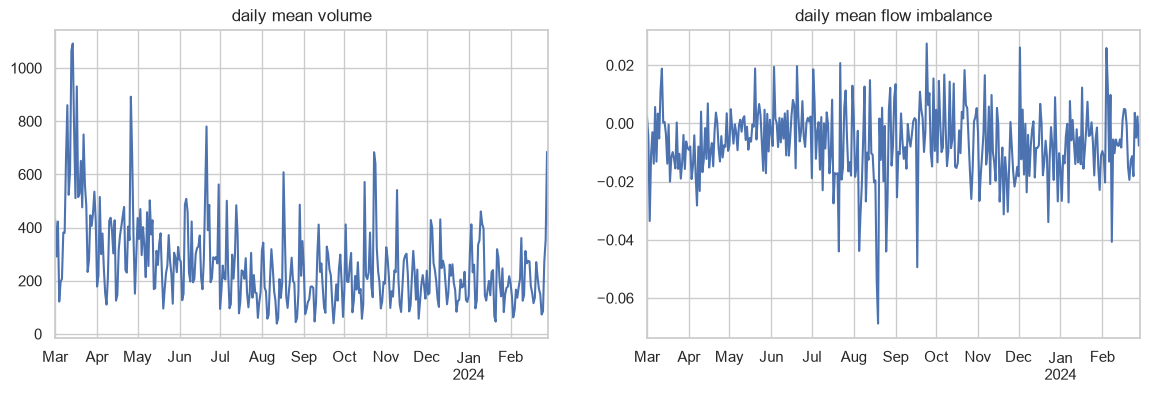

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
train["volume"].resample("1D").mean().plot(ax=ax[0], title="daily mean volume")
derived["flow_imbalance"].resample("1D").mean().plot(ax=ax[1], title="daily mean flow imbalance")
plt.show()

## 5. The anonymized X features

No documentation exists for these, so we characterize them statistically: scale, sparsity, linear relation to the target, and redundancy among themselves.

In [9]:
desc = train[xcols].describe().T
print("std quantiles across X columns:")
print(desc["std"].quantile([0, 0.25, 0.5, 0.75, 1]).to_string())
zero_share = (train[xcols] == 0).mean()
print(f"\nX columns that are >50% zeros: {(zero_share > 0.5).sum()}   >99% zeros: {(zero_share > 0.99).sum()}")

std quantiles across X columns:
0.00    0.359641
0.25    0.826387
0.50    0.921770
0.75    1.019223
1.00    1.433086



X columns that are >50% zeros: 0   >99% zeros: 0


|corr| with label: max 0.0906, median 0.0139


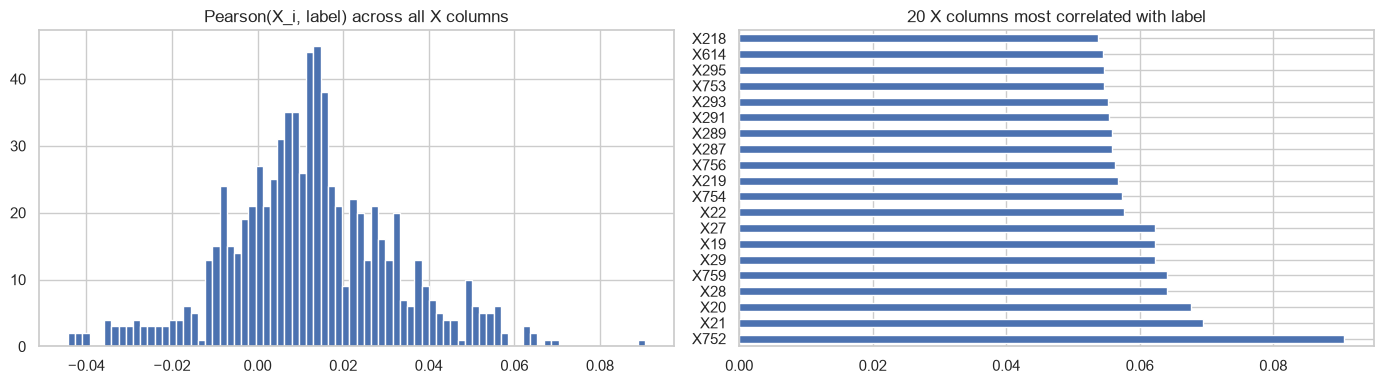

In [10]:
x_corr = train[xcols].corrwith(y).sort_values()
print(f"|corr| with label: max {x_corr.abs().max():.4f}, median {x_corr.abs().median():.4f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].hist(x_corr, bins=80)
ax[0].set_title("Pearson(X_i, label) across all X columns")
top = x_corr.abs().sort_values(ascending=False).head(20)
x_corr[top.index].plot.barh(ax=ax[1], title="20 X columns most correlated with label")
plt.tight_layout()
plt.show()

X column pairs that are near duplicates (50k-row sample):


|corr| > 0.95    454
|corr| > 0.99    113


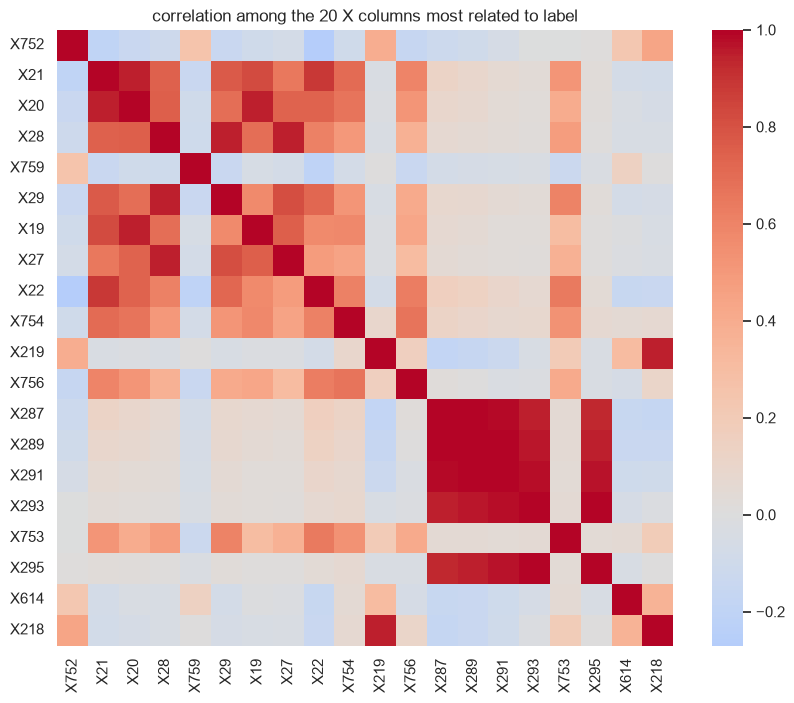

In [11]:
print("X column pairs that are near duplicates (50k-row sample):")
print(redundant_pairs(train[xcols]).to_string())

plt.figure(figsize=(10, 8))
sns.heatmap(train[top.index].sample(50_000, random_state=0).corr(), cmap="coolwarm", center=0, square=True)
plt.title("correlation among the 20 X columns most related to label")
plt.show()

## 6. Train vs test drift

Test timestamps are masked, so we cannot compare by date. Instead we compare feature distributions directly and train a classifier to tell train rows from test rows (adversarial validation). AUC near 0.5 means the two sets look alike; AUC near 1 means strong drift.

,train_mean,test_mean,train_std,test_std
bid_qty,9.970000,6.630000,15.650000,10.420000
ask_qty,10.170000,6.760000,15.890000,12.220000
buy_qty,131.710007,85.000000,307.179993,158.860001
sell_qty,132.660004,86.169998,309.730011,165.029999
volume,264.369995,171.169998,588.460022,303.459991


adversarial validation AUC: 1.000


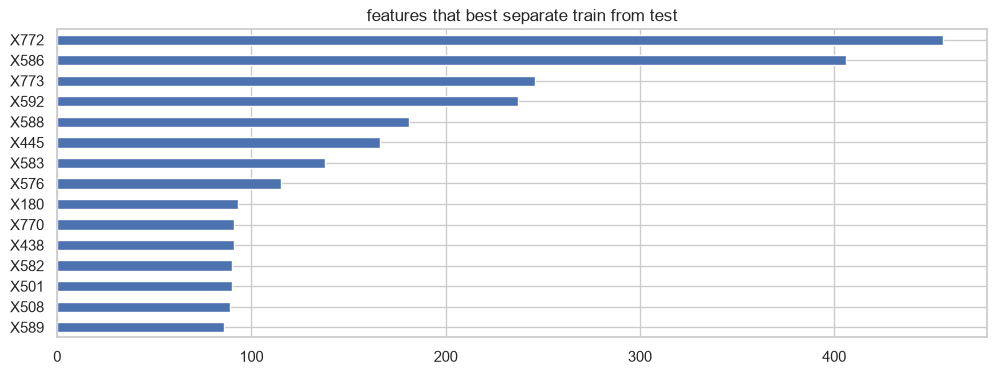

,train_mean,test_mean,train_std,test_std
X772,0.169,-0.143,1.092,0.862
X586,0.582,-0.516,1.070,0.500
X773,-0.001,0.001,0.720,1.166
X592,0.585,-0.509,1.103,0.493
X588,-0.780,0.669,0.795,0.601
X445,-0.027,-0.004,1.075,0.907
X583,0.735,-0.635,0.922,0.514
X576,-0.728,0.623,0.793,0.700


single-feature AUC: max 0.993 (X772), features above 0.9: 6, above 0.75: 20


,X772,X586,X592,X583,X589,X588,X576,X564,X582,X570
AUC,0.993,0.938,0.929,0.92,0.908,0.904,0.896,0.882,0.876,0.861


In [12]:
shift = pd.DataFrame({
    "train_mean": train[MARKET_COLS].mean(),
    "test_mean": test[MARKET_COLS].mean(),
    "train_std": train[MARKET_COLS].std(),
    "test_std": test[MARKET_COLS].std(),
})
display(shift.round(2))

feats = feature_columns(train)
auc, importances, single_auc = adversarial_validation(train, test, feats)
print(f"adversarial validation AUC: {auc:.3f}")
importances.head(15).plot.barh(title="features that best separate train from test")
plt.gca().invert_yaxis()
plt.show()

top_drift = importances.index[:8]
display(pd.DataFrame({
    "train_mean": train[top_drift].mean(), "test_mean": test[top_drift].mean(),
    "train_std": train[top_drift].std(), "test_std": test[top_drift].std(),
}).round(3))

print(f"single-feature AUC: max {single_auc.max():.3f} ({single_auc.index[0]}), "
      f"features above 0.9: {(single_auc > 0.9).sum()}, above 0.75: {(single_auc > 0.75).sum()}")
single_auc.head(10).round(3).to_frame("AUC").T

## 7. Time structure

Crypto trades 24/7 but activity still follows the clock. We check hour-of-day and day-of-week patterns in volume and in the target's volatility.

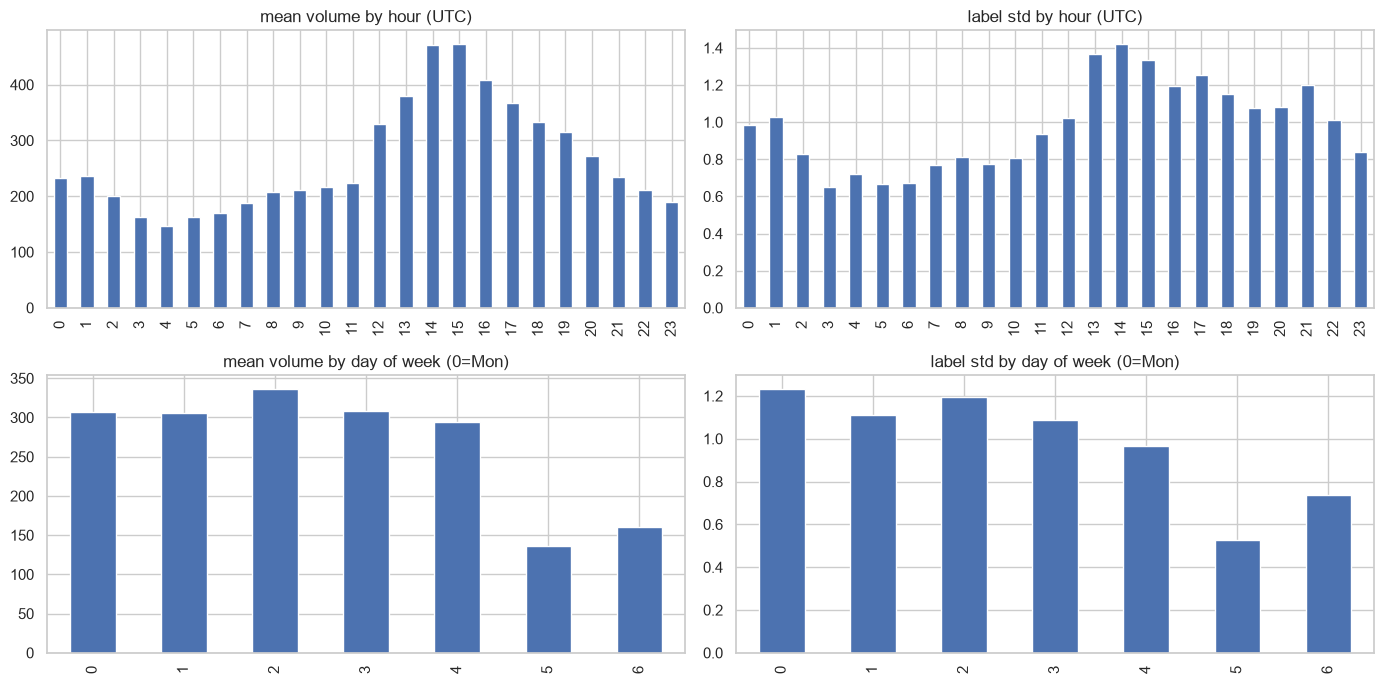

In [13]:
by_hour = train.groupby(train.index.hour).agg(volume=("volume", "mean"), label_std=(TARGET, "std"))
by_dow = train.groupby(train.index.day_of_week).agg(volume=("volume", "mean"), label_std=(TARGET, "std"))
fig, ax = plt.subplots(2, 2, figsize=(14, 7))
by_hour["volume"].plot.bar(ax=ax[0, 0], title="mean volume by hour (UTC)")
by_hour["label_std"].plot.bar(ax=ax[0, 1], title="label std by hour (UTC)")
by_dow["volume"].plot.bar(ax=ax[1, 0], title="mean volume by day of week (0=Mon)")
by_dow["label_std"].plot.bar(ax=ax[1, 1], title="label std by day of week (0=Mon)")
plt.tight_layout()
plt.show()

## 8. Baselines

Validation protocol: the first 80% of the training period is used to fit, the last 20% is the holdout.
The split is chronological because `label` is a future price move. A shuffled split would place
neighbouring minutes on both sides and leak the future into training. One day of rows (1,440) is
dropped right before the holdout, because the label's autocorrelation only vanishes at a lag of about
a day (section 3), so rows on both sides of the cut would otherwise share future information.
The metric is Pearson correlation, the same as the competition.

In [14]:
fit_df, val_df = time_split(train)
feats = feature_columns(train)
print(f"fit : {fit_df.index.min()} to {fit_df.index.max()}  ({len(fit_df):,} rows)")
print(f"val : {val_df.index.min()} to {val_df.index.max()}  ({len(val_df):,} rows)")

holdout = {}
for name, make in BASELINES.items():
    model = make().fit(fit_df[feats], fit_df[TARGET])
    holdout[name] = pearson(val_df[TARGET], model.predict(val_df[feats]))
    print(f"{name:14s} holdout Pearson = {holdout[name]:.4f}")

fit : 2023-03-01 00:00:00 to 2023-12-17 20:00:00  (419,268 rows)
val : 2023-12-18 20:01:00 to 2024-02-29 23:59:00  (105,178 rows)
constant_mean  holdout Pearson = 0.0000


ridge          holdout Pearson = 0.0958


lightgbm       holdout Pearson = 0.0536


### Kaggle submissions

Each baseline is refit on the full training set and its test predictions are written to `submissions/`. The three files were uploaded to Kaggle on 2026-11-06. The competition is closed, so these are late submissions: they are scored but not ranked. The submit cell is guarded by `SUBMIT` so that re-running the notebook does not create duplicate submissions. Scores are in section 9.

In [15]:
os.makedirs("submissions", exist_ok=True)
for name, make in BASELINES.items():
    model = make().fit(train[feats], train[TARGET])
    write_submission(test.index, model.predict(test[feats]), f"submissions/{name}.csv")
    print("wrote", f"submissions/{name}.csv")

wrote submissions/constant_mean.csv


wrote submissions/ridge.csv


wrote submissions/lightgbm.csv


In [16]:
SUBMIT = False  # set to True to submit the files in submissions/ again
if SUBMIT:
    for name in BASELINES:
        !kaggle competitions submit -c drw-crypto-market-prediction -f submissions/{name}.csv -m "Assignment 1 baseline: {name}"

## 9. Results and takeaways

| Baseline | Holdout Pearson | Kaggle public | Kaggle private |
|---|---|---|---|
| `constant_mean` | 0.0000 | 0.0000 | 0.0000 |
| `ridge` | 0.0958 | 0.0244 | 0.0476 |
| `lightgbm` | 0.0536 | 0.0526 | 0.0338 |

Fit period 2023-03-01 to 2023-12-17 20:00 (419,268 rows), one day dropped, holdout 2023-12-18 20:01 to 2024-02-29 23:59 (105,178 rows). Kaggle scores come from the three files in `submissions/`, produced by the same models refit on the full training set and uploaded on 2026-11-06 as late submissions (scored after the deadline, not ranked).

**Data.** 525,886 training minutes (2023-03-01 to 2024-02-29) and 538,150 test minutes with masked timestamps. 786 columns: 5 market features, 780 anonymized `X` features and `label`. No missing values, no constant columns, no duplicate timestamps. The minute grid is 99.8% complete: 273 gaps add up to 1,154 missing minutes, most gaps are 2 to 8 minutes long and the longest is 35 minutes.

**Target.** `label` is centred near zero with unit scale but heavy tails (kurtosis 16, range -24 to 21). Its autocorrelation is 0.98 at one minute, 0.61 at 30 minutes, 0.38 at one hour and about zero at one day. Neighbouring rows share most of their target, so a shuffled train/validation split would leak the future. That is why validation is chronological with a one-day embargo. The daily volatility of the label changes visibly across the year, so model performance will depend on the regime.

**Market features.** Each of the five public features has a tiny linear relation to the target (|Pearson| below 0.02), and so do the order-book and trade-flow imbalance ratios derived from them. Any value they carry must come from interactions or rolling context rather than from the raw minute values.

**Anonymized features.** The `X` columns are dense and already roughly standardized (std between 0.36 and 1.43). Individually they are weak (max |Pearson| with the target 0.09, median 0.014) and strongly redundant: on a 50k-row sample, 454 pairs correlate above 0.95 and 113 above 0.99. Feature selection or decorrelation is an obvious step for Assignment 2.

**Drift.** Train and test are trivially separable (adversarial validation AUC 1.00). The separation is concentrated in a small group of `X` features whose level shifts between the two periods: `X772` alone reaches AUC 0.99, six features exceed 0.9, and several flip sign (for example `X586` averages 0.58 in train and -0.52 in test). Test volume is also about 35% lower than in train. The test period is therefore a different market regime, and features whose level drifts like this cannot be trusted by a model trained on one period and applied to another. This may be part of why holdout scores do not carry over one-to-one to Kaggle: ridge drops from 0.096 on the holdout to 0.024 public / 0.048 private, while LightGBM stays closer (0.054 against 0.053 / 0.034).

**Baselines.** Both learned models clearly beat the zero-information baseline but stay below 0.1 Pearson on every surface, so the usable signal is weak. Ridge is the stronger baseline on our holdout and on the private leaderboard, LightGBM on the public leaderboard. These three rows are the reference Assignment 2 has to beat.

**Directions for Assignment 2.** Drift-robust features (rolling or rank normalization, dropping the drifting `X` block), removal of redundant `X` columns, several chronological validation folds instead of one, early stopping for the boosted trees, and a blend of the linear and tree models.